# 21 — Evaluación: prueba, importancia de variables y tres versiones del modelo
Punto **3** del informe. Tres preguntas:

1. **¿Qué tan bien estiman los modelos el tiempo de procesos que nunca vieron?** Se usa por primera vez el 20 % de
   prueba, que ningún modelo vio.
2. **¿Qué variables usa el modelo?** Importancia **por permutación**: se desordena una variable (se barajan sus valores
   entre filas) y se mide cuánto **sube el error**. Si sube mucho, el modelo dependía de ella; si no sube, la ignoraba.
   Sirve para cualquier modelo, incluido el SVM, que no tiene importancias propias. Se mide en los pliegues de validación
   del **entrenamiento**, no en la prueba, para que elegir las variables no «espíe» los datos con que se evalúa.
3. **¿Cuántas variables hacen falta?** Se comparan tres versiones: las **19 originales**, las **28 con ingeniería e
   historia** y solo las **5 más importantes**.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
import warnings
from sklearn.model_selection import GroupKFold, cross_val_score

warnings.filterwarnings("ignore", category=FutureWarning)
datos = cargar_conjunto()
part = pd.read_csv(MODELO_DIR / "particion.csv")
assert np.allclose(part[OBJETIVO].to_numpy(), datos[OBJETIVO].to_numpy())
tr = part.index[part["particion"] == "entrenamiento"]
te = part.index[part["particion"] == "prueba"]
y_tr, y_te = datos.loc[tr, OBJETIVO], datos.loc[te, OBJETIVO]
hp = leer_hp()
metricas_cv = pd.read_csv(MODELO_DIR / "metricas_cv.csv")
ajustado_cv = metricas_cv[metricas_cv["configuracion"] == "ajustado"].set_index("modelo")
MEJOR = ajustado_cv.loc[ENTRENABLES, "mae_log"].idxmin()
print(len(tr), "entrenamiento,", len(te), "prueba; mejor modelo en validación cruzada:", MEJOR)

646 entrenamiento, 162 prueba; mejor modelo en validación cruzada: Stacking


## 3.1 Métricas en la prueba
| métrica | pregunta que responde |
|---|---|
| MAE (log) | en promedio, ¿por cuánto se equivoca, en la escala en que «el doble» pesa igual para todos? |
| dentro del doble | de cada 100 procesos, ¿en cuántos el tiempo real quedó entre la mitad y el doble de lo estimado? |
| factor mediano | la mitad de las estimaciones se equivoca por menos que este factor |
| R² (log) | ¿qué parte de las diferencias de tiempo entre procesos explica? |
| error mediano en días | el error típico, en días |

In [2]:
ajustados, filas = {}, []
for nombre in MODELOS:
    m = modelo(nombre, COMPLETA, hp).fit(datos.loc[tr, COMPLETA], y_tr)
    ajustados[nombre] = m
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0],
                  **medir(y_te, m.predict(datos.loc[te, COMPLETA])),
                  "mae_log_cv": ajustado_cv.loc[nombre, "mae_log"]})
metricas_test = pd.DataFrame(filas)
metricas_test.to_csv(MODELO_DIR / "metricas_test.csv", index=False)
display(metricas_test.set_index("modelo").round(3))

,familia,mae_log,factor_mediano,dentro_doble,r2_log,error_dias_mediano,mae_log_cv
modelo,,,,,,,
Línea base (promedio),referencia,1.078,2.245,0.420,-0.002,152.016,1.085
Fórmula ingenua,referencia,0.858,1.714,0.654,0.106,94.807,0.888
Regresión lineal (Ridge),referencia,0.718,1.667,0.642,0.496,97.255,0.787
SVM,SVM,0.697,1.540,0.648,0.411,92.913,0.751
Bagging,Bagging,0.731,1.542,0.679,0.386,76.777,0.752
Random Forest,Bagging,0.736,1.588,0.636,0.352,80.986,0.752
AdaBoost,Boosting,0.772,1.632,0.667,0.300,96.621,0.755
Gradient Boosting,Boosting,0.710,1.534,0.679,0.387,84.538,0.746
Stacking,Stacking,0.694,1.518,0.673,0.409,86.734,0.738


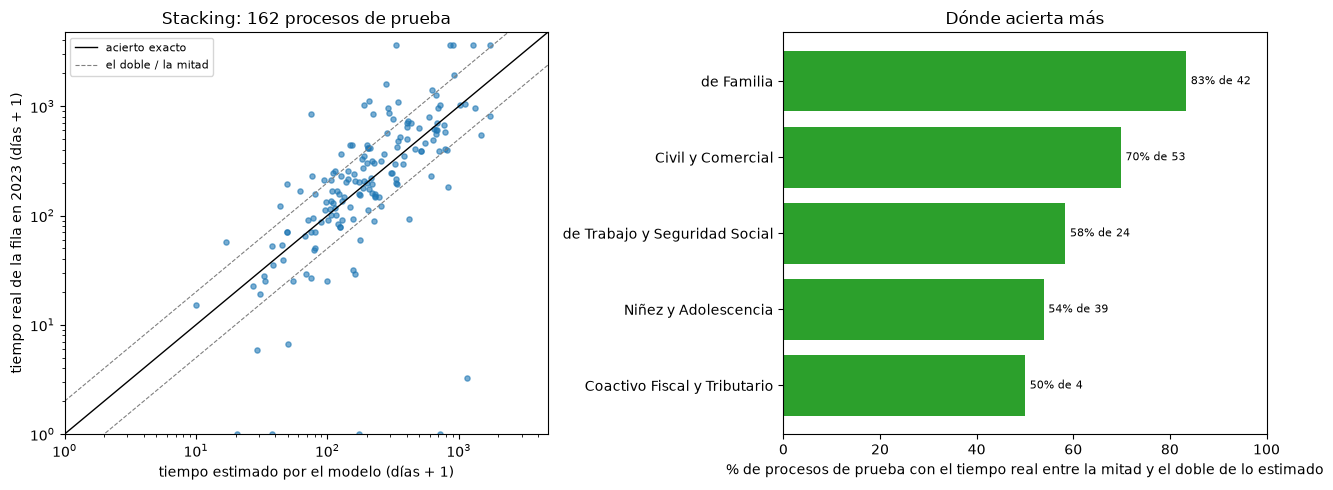

,procesos,dentro_doble
materia_homologada,,
Partido Administrativo Coactivo Fiscal y Tributario,4,0.500
Público Niñez y Adolescencia,39,0.538
Partido de Trabajo y Seguridad Social,24,0.583
Público Civil y Comercial,53,0.698
Público de Familia,42,0.833


In [3]:
pred_mejor = ajustados[MEJOR].predict(datos.loc[te, COMPLETA])
real_d, pred_d = np.expm1(y_te.to_numpy()), np.expm1(pred_mejor)
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ax = ejes[0]
ax.scatter(pred_d + 1, real_d + 1, s=14, alpha=0.6, color="tab:blue")
lim = [1, TOPE_DIAS * 1.3]
ax.plot(lim, lim, color="black", lw=1, label="acierto exacto")
ax.plot(lim, [2 * v for v in lim], color="gray", ls="--", lw=0.8, label="el doble / la mitad")
ax.plot(lim, [v / 2 for v in lim], color="gray", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("tiempo estimado por el modelo (días + 1)")
ax.set_ylabel("tiempo real de la fila en 2023 (días + 1)")
ax.set_title(f"{MEJOR}: {len(te)} procesos de prueba")
ax.legend(fontsize=8)
ax = ejes[1]
prueba = datos.loc[te].assign(err=np.abs(pred_mejor - y_te.to_numpy()))
por_materia = (prueba.groupby("materia_homologada")["err"]
               .agg(procesos="size", dentro_doble=lambda e: (e <= np.log(2)).mean()).sort_values("dentro_doble"))
etiquetas = [m.replace("Público ", "").replace("Partido ", "").replace("Administrativo ", "") for m in por_materia.index]
ax.barh(etiquetas, por_materia["dentro_doble"] * 100, color="tab:green")
for i, (v, n) in enumerate(zip(por_materia["dentro_doble"], por_materia["procesos"])):
    ax.text(v * 100 + 1, i, f"{v:.0%} de {n}", va="center", fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("% de procesos de prueba con el tiempo real entre la mitad y el doble de lo estimado")
ax.set_title("Dónde acierta más")
plt.tight_layout()
guardar_figura(fig, "nb21_1.png")
plt.show()
por_materia.to_csv(MODELO_DIR / "prueba_por_materia.csv")
display(por_materia.round(3))

¿Acierta mejor en los procesos grandes? Un proceso con miles de causas tiene un tiempo más estable que uno con 15.

In [4]:
causas = datos.loc[te, "atendidas"]
tamanos = pd.cut(causas, [MIN_CAUSAS - 1, 30, 100, 500, np.inf], labels=["10-30", "31-100", "101-500", "más de 500"])
por_tamano = (prueba.assign(tamano=tamanos.to_numpy()).groupby("tamano", observed=True)["err"]
              .agg(procesos="size", mae_log="mean", dentro_doble=lambda e: (e <= np.log(2)).mean()))
por_tamano.to_csv(MODELO_DIR / "prueba_por_tamano.csv")
display(por_tamano.round(3))

,procesos,mae_log,dentro_doble
tamano,,,
10-30,43,0.911,0.465
101-500,37,0.738,0.784
31-100,48,0.745,0.625
más de 500,34,0.300,0.882


## 3.2 Importancia de las variables
Por permutación sobre el mejor modelo (5 pliegues × 10 barajadas por variable). Como comparación, la importancia por
**impureza** del Random Forest (cuánto ayuda cada variable a reducir el error en los cortes de los árboles; las
columnas one-hot de una categoría se suman). La impureza tiende a favorecer variables con muchos valores distintos;
por eso la selección usa la permutación.

In [5]:
imp = importancia_permutacion_cv(MEJOR, COMPLETA, datos.loc[tr].reset_index(drop=True), y_tr.reset_index(drop=True), hp)
rf = ajustados["Random Forest"]
nombres_salida = rf.named_steps["pre"].get_feature_names_out()
impureza = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres_salida)
impureza_var = {c: impureza[[n for n in nombres_salida if n == f"num__{c}" or n.startswith(f"cat__{c}_")]].sum()
                for c in COMPLETA}
imp["importancia_impureza_rf"] = pd.Series(impureza_var)
imp["nombre"] = [NOMBRES[c] for c in imp.index]
imp["grupo"] = ["original" if c in ORIGINALES else ("histórica" if c in HISTORICAS else "ingeniería") for c in imp.index]
imp["rango"] = range(1, len(imp) + 1)
imp.index.name = "variable"
imp.to_csv(MODELO_DIR / "importancia.csv")
TOP5 = list(imp.index[:5])
(MODELO_DIR / "top5.json").write_text(json.dumps({"modelo_importancia": MEJOR, "variables": TOP5}, ensure_ascii=False, indent=2),
                                      encoding="utf-8")
display(imp.round(4))
print("las 5 más importantes:", TOP5)
assert abs(imp["importancia_impureza_rf"].sum() - 1) < 1e-9

,importancia,desvio_entre_pliegues,importancia_impureza_rf,nombre,grupo,rango
variable,,,,,,
log_stock_inicial,0.1549,0.0988,0.0444,log del stock heredado,ingeniería,1
presion_stock,0.1455,0.0773,0.3666,presión del stock,ingeniería,2
log_ingresos,0.1233,0.0686,0.0334,log de los ingresos,ingeniería,3
ingresos_por_juzgado,0.0548,0.0135,0.0721,ingresos por juzgado,ingeniería,4
stock_por_juzgado,0.0264,0.0185,0.0617,stock por juzgado,ingeniería,5
pendientes_inicio_efectivo,0.0149,0.0153,0.0466,stock heredado,original,6
departamento_derivado,0.0137,0.0111,0.0116,departamento,original,7
personal_items_mujer,0.0105,0.0090,0.0188,puestos ocupados por mujeres,original,8
materia_homologada,0.0095,0.0073,0.0315,materia,original,9


las 5 más importantes: ['log_stock_inicial', 'presion_stock', 'log_ingresos', 'ingresos_por_juzgado', 'stock_por_juzgado']


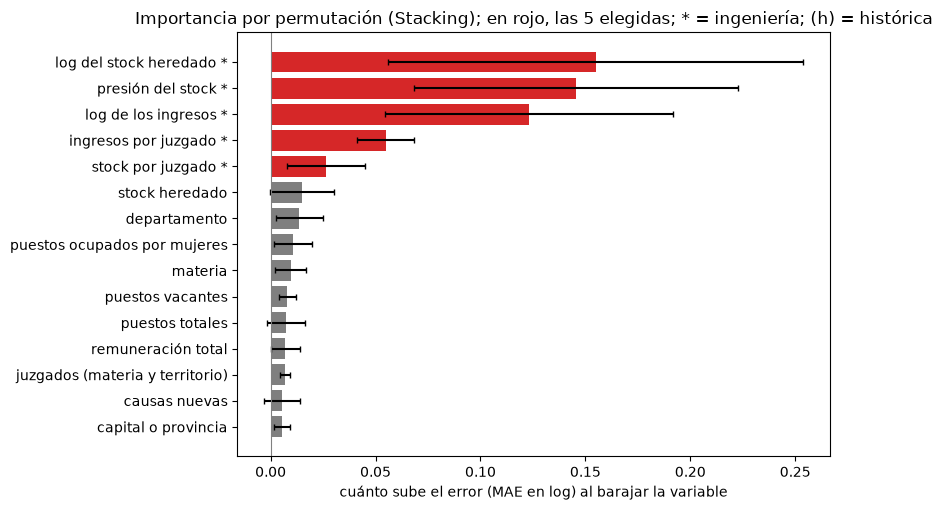

In [6]:
vista = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
colores_barras = ["tab:red" if c in TOP5 else "tab:gray" for c in vista.index]
marca = {c: (" *" if c in INGENIERIA else (" (h)" if c in HISTORICAS else "")) for c in vista.index}
ax.barh([f"{vista.loc[c, 'nombre']}{marca[c]}" for c in vista.index], vista["importancia"],
        xerr=vista["desvio_entre_pliegues"], color=colores_barras, ecolor="black", capsize=2)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("cuánto sube el error (MAE en log) al barajar la variable")
ax.set_title(f"Importancia por permutación ({MEJOR}); en rojo, las 5 elegidas; * = ingeniería; (h) = histórica")
plt.tight_layout()
guardar_figura(fig, "nb21_3.png")
plt.show()

## 3.3 Tres versiones: 19, 28 y 5 variables
Cada modelo se entrena con cada conjunto de variables, con los hiperparámetros del notebook 20. Se reporta el error de
validación cruzada (entrenamiento) y el de la prueba.

In [7]:
VERSIONES = {"originales (19)": ORIGINALES, "con ingeniería e historia (28)": COMPLETA, "5 más importantes": TOP5}
assert len(ORIGINALES) == 19 and len(COMPLETA) == 28 and len(TOP5) == 5
filas = []
for version, cols in VERSIONES.items():
    for nombre in ENTRENABLES:
        cv_mae = -cross_val_score(modelo(nombre, cols, hp), datos.loc[tr, cols], y_tr, cv=CV5, scoring=ESCORE, n_jobs=-1)
        m = modelo(nombre, cols, hp).fit(datos.loc[tr, cols], y_tr)
        r = medir(y_te, m.predict(datos.loc[te, cols]))
        filas.append({"version": version, "n_variables": len(cols), "modelo": nombre, "mae_log_cv": cv_mae.mean(),
                      "mae_log_cv_desvio": cv_mae.std(), "mae_log_prueba": r["mae_log"],
                      "dentro_doble_prueba": r["dentro_doble"], "r2_log_prueba": r["r2_log"]})
versiones = pd.DataFrame(filas)
versiones.to_csv(MODELO_DIR / "comparacion_versiones.csv", index=False)
display(versiones.pivot_table(index="modelo", columns="version", values=["mae_log_cv", "mae_log_prueba"]).round(3))
display(versiones.pivot_table(index="modelo", columns="version", values="dentro_doble_prueba").round(3))

mae_log_cv                                 \
version                  5 más importantes con ingeniería e historia (28)   
modelo                                                                      
AdaBoost                             0.814                          0.755   
Bagging                              0.820                          0.752   
Gradient Boosting                    0.794                          0.746   
Random Forest                        0.807                          0.752   
Regresión lineal (Ridge)             0.800                          0.787   
SVM                                  0.773                          0.751   
Stacking                             0.770                          0.738   

                                            mae_log_prueba  \
version                  originales (19) 5 más importantes   
modelo                                                       
AdaBoost                           0.862             0.767   
Bagging                            0.815             0.756   
Gradient Boosting                  0.809             0.725   
Random Forest                      0.830             0.753   
Regresión lineal (Ridge)           0.921             0.695   
SVM                                0.850             0.718   
Stacking                           0.796             0.716   

                                                                         
version                  con ingeniería e historia (28) originales (19)  
modelo                                                                   
AdaBoost                                          0.772           0.900  
Bagging                                           0.731           0.821  
Gradient Boosting                                 0.710           0.777  
Random Forest                                     0.736           0.828  
Regresión lineal (Ridge)                          0.718           0.943  
SVM                                               0.697           0.844  
Stacking                                          0.694           0.770

version,5 más importantes,con ingeniería e historia (28),originales (19)
modelo,,,
AdaBoost,0.648,0.667,0.562
Bagging,0.630,0.679,0.543
Gradient Boosting,0.679,0.679,0.605
Random Forest,0.617,0.636,0.556
Regresión lineal (Ridge),0.667,0.642,0.469
SVM,0.710,0.648,0.574
Stacking,0.698,0.673,0.593


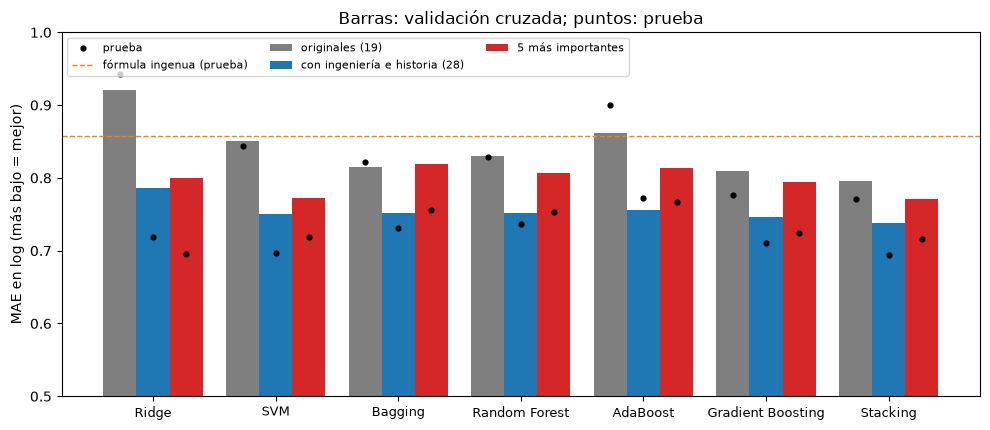

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.4))
pos = np.arange(len(ENTRENABLES))
for k, (version, color) in enumerate(zip(VERSIONES, ["tab:gray", "tab:blue", "tab:red"])):
    v = versiones[versiones["version"] == version].set_index("modelo").loc[ENTRENABLES]
    ax.bar(pos + (k - 1) * 0.27, v["mae_log_cv"], 0.27, color=color, label=version)
    ax.scatter(pos + (k - 1) * 0.27, v["mae_log_prueba"], color="black", s=12, zorder=3,
               label="prueba" if k == 0 else None)
ref_ing = metricas_test.set_index("modelo").loc["Fórmula ingenua", "mae_log"]
ax.axhline(ref_ing, color="tab:orange", ls="--", lw=1, label="fórmula ingenua (prueba)")
ax.set_xticks(pos, [m.replace("Regresión lineal (Ridge)", "Ridge") for m in ENTRENABLES], fontsize=9)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("MAE en log (más bajo = mejor)")
ax.set_title("Barras: validación cruzada; puntos: prueba")
ax.legend(fontsize=8, ncol=3, loc="upper left")
plt.tight_layout()
guardar_figura(fig, "nb21_4.png")
plt.show()

## 3.4 Control de robustez: procesos que el modelo nunca vio
El mismo tipo de proceso (por ejemplo, «divorcio») aparece en varios departamentos. Si el modelo solo «recordara» cada
tipo, le iría bien en la validación normal pero mal con un tipo nuevo. Con **validación por grupos** (`GroupKFold`)
todas las filas de un mismo tipo de proceso quedan del mismo lado: el modelo se evalúa con tipos que no vio al entrenar.

In [9]:
grupos = datos.loc[tr, "tipo_proceso"]
filas = []
for version, cols in VERSIONES.items():
    for nombre in dict.fromkeys([MEJOR, "Random Forest", "SVM"]):
        g = -cross_val_score(modelo(nombre, cols, hp), datos.loc[tr, cols], y_tr, groups=grupos, cv=GroupKFold(5),
                             scoring=ESCORE, n_jobs=-1)
        normal = versiones.set_index(["version", "modelo"]).loc[(version, nombre), "mae_log_cv"]
        filas.append({"version": version, "modelo": nombre, "mae_log_cv_normal": normal, "mae_log_por_grupos": g.mean(),
                      "diferencia": g.mean() - normal})
robustez = pd.DataFrame(filas)
robustez.to_csv(MODELO_DIR / "robustez_grupos.csv", index=False)
display(robustez.round(3))
print(datos["tipo_proceso"].nunique(), "tipos de proceso distintos")

,version,modelo,mae_log_cv_normal,mae_log_por_grupos,diferencia
0,originales (19),Stacking,0.796,0.810,0.014
1,originales (19),Random Forest,0.830,0.822,-0.008
2,originales (19),SVM,0.850,0.875,0.025
3,con ingeniería e historia (28),Stacking,0.738,0.764,0.026
4,con ingeniería e historia (28),Random Forest,0.752,0.766,0.014
5,con ingeniería e historia (28),SVM,0.751,0.812,0.061
6,5 más importantes,Stacking,0.770,0.778,0.007
7,5 más importantes,Random Forest,0.807,0.831,0.024
8,5 más importantes,SVM,0.773,0.771,-0.002


78 tipos de proceso distintos


## Lectura
- **En la prueba (162 procesos que ningún modelo vio) los resultados se sostienen e incluso mejoran un poco.** Stacking:
  error 0,694 en log, **67 %** de los procesos con el tiempo real entre la mitad y el doble de lo estimado, factor mediano
  ×1,52 (la mitad de las estimaciones se equivoca por menos de 52 % de más o de menos), R² 0,41 y un error mediano de **87
  días**. Las referencias: línea base 1,078 (42 % dentro del doble) y fórmula ingenua 0,858 (65 %, pero R² 0,11).
- **Con 162 procesos, diferencias de 0,02 entre modelos están dentro del ruido.** En la prueba la regresión lineal (0,718)
  queda casi igual que los ensambles; en validación cruzada había quedado atrás. Ningún modelo gana con claridad.
- **Acierta mucho más en los procesos grandes:** dentro del doble en el 47 % de los procesos con 10 a 30 causas, 62 % con
  31 a 100, 78 % con 101 a 500 y **88 % con más de 500**. Tiene sentido: en un proceso con miles de causas la fila es
  estable; en uno con 15, una sola causa cambia mucho el tiempo. Por eso la página da rangos más anchos a los procesos chicos.
- **Por materia:** acierta más en Familia (83 % dentro del doble) y Civil (70 %) que en Niñez (54 %) y Trabajo (58 %).
- **Importancia:** lo que más usa el modelo es la **carga en relación con la capacidad**: log del stock heredado (al
  barajarlo el error sube 0,155), presión del stock (0,146), log de los ingresos (0,123), ingresos por juzgado (0,055) y
  stock por juzgado (0,026). Son las 5 elegidas, y **todas salen de solo 3 datos**: stock heredado, ingresos y juzgados.
  Personal, vacantes, remuneración y ámbito importan poco (< 0,011). La **variable histórica** queda en el puesto 17 (0,005):
  el ritmo nacional de la materia casi no dice nada del tiempo de un proceso concreto; la historia sirvió más para validar
  la medida (notebook 19) que como pista del modelo.
- **Tres versiones:** con ingeniería e historia (28) es la mejor en todos los modelos (Stacking 0,738 en validación,
  0,694 en la prueba). Las 19 originales pierden bastante (Stacking 0,796 y 0,770; Ridge 0,921): **los cocientes y logaritmos
  que arma la ingeniería son la mitad de la señal**. Las **5 más importantes quedan cerca de las 28** (Stacking 0,770 y
  0,716; SVM 0,773 y 0,718): el modelo pequeño casi no pierde, porque las 5 ya concentran la carga y la capacidad.
- **Robustez:** al evaluar con tipos de proceso que el modelo no vio (`GroupKFold`), el Stacking de 28 variables sube de
  0,738 a 0,764 (+0,026) y el de 5 variables apenas +0,007: el modelo no «recuerda» cada tipo de proceso, generaliza a tipos
  nuevos. El SVM con 28 variables es el que más pierde (+0,061).